In [10]:
%pip install pandas numpy scipy scikit-learn matplotlib



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

SELECTED_PATH = Path('data/US_selected_transactions.csv')
FULL_PATH = Path('data/valid_US_Enterprise.csv')
OUTPUT = Path('baseline_results'); OUTPUT.mkdir(exist_ok=True)
print('Working directory:', Path.cwd())


Working directory: /Users/shambhavikhanna/Downloads/Capstone


In [12]:
for path in [SELECTED_PATH, FULL_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Cannot find {path.resolve()}. Update the path in Step 2."
        )
selected_raw = pd.read_csv(SELECTED_PATH, low_memory=False)
full_raw = pd.read_csv(FULL_PATH, low_memory=False)
print('Selected:', selected_raw.shape)
print('Full:', full_raw.shape)
display(selected_raw.head())
display(full_raw.head())


Selected: (129920, 36)
Full: (2715704, 35)


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,pricing_date
0,2026-05-29,NaN,2026-05-31,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,OH,...,1150.15,419.250024,NaN,NaN,$1500 - $1699,NaN,Sub-Family Insight Ground,Product Family Knight Thrive,Product Group Peak Flare,2026-05-31
1,2026-05-29,NaN,2026-05-30,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,IA,...,1893.66,443.489902,NaN,NaN,$2000+,NaN,Sub-Family Signal Hawk,Product Family Solar Peak,Product Group Peak Flare,2026-05-30
2,2026-05-29,NaN,2026-06-01,2026-06-01,June,FY27Q1,Invoice,Standard Invoice,DP52705656,GA,...,917.85,137.530005,NaN,NaN,$1000 - $1299,NaN,Sub-Family Insight Ground,Product Family Knight Thrive,Product Group Peak Flare,2026-06-01
3,2026-05-29,NaN,2026-05-30,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,WI,...,2473.05,541.419971,NaN,NaN,$2000+,NaN,Sub-Family Reign Junction,Product Family Solar Peak,Product Group Peak Flare,2026-05-30
4,2026-05-29,NaN,2026-05-30,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP52705656,CA,...,2473.05,835.950000,NaN,NaN,$2000+,NaN,Sub-Family Reign Junction,Product Family Solar Peak,Product Group Peak Flare,2026-05-30


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,tax,cost,margin,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group
0,2026-05-29,NaN,2026-05-31,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,OH,...,123.20,1150.15,419.250024,NaN,NaN,$1500 - $1699,NaN,Sub-Family Insight Ground,Product Family Knight Thrive,Product Group Peak Flare
1,2026-05-29,NaN,2026-05-30,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,NJ,...,76.78,904.89,254.110000,NaN,NaN,$1000 - $1299,Tele,Sub-Family Fortune Horizon,Product Family Knight Thrive,Product Group Peak Flare
2,2026-05-29,NaN,2026-06-03,2026-06-01,June,FY27Q1,Invoice,Standard Invoice,DP52705656,WI,...,135.73,1485.87,814.559932,NaN,NaN,$2000+,NaN,Sub-Family Nexus Glide,Product Family Frame Road,Product Group Peak Flare
3,2026-05-29,NaN,2026-05-30,2026-05-25,May,FY27Q1,Invoice,Standard Invoice,DP63844849,IA,...,140.34,1893.66,443.489902,NaN,NaN,$2000+,NaN,Sub-Family Signal Hawk,Product Family Solar Peak,Product Group Peak Flare
4,2026-05-29,NaN,2026-06-03,2026-06-01,June,FY27Q1,Invoice,Standard Invoice,DP63844849,NY,...,81.13,1063.70,47.029980,NaN,NaN,$1000 - $1299,NaN,Sub-Family Insight Ground,Product Family Knight Thrive,Product Group Peak Flare


In [13]:
# Remove accidental whitespace from column names.
selected_raw.columns = selected_raw.columns.str.strip()
full_raw.columns = full_raw.columns.str.strip()

# Check whether pricing_date in the selected file matches ship_date.
if {"pricing_date", "ship_date"}.issubset(selected_raw.columns):
    pricing_dates = pd.to_datetime(
        selected_raw["pricing_date"], errors="coerce"
    ).dt.normalize()

    shipping_dates = pd.to_datetime(
        selected_raw["ship_date"], errors="coerce"
    ).dt.normalize()

    comparable = pricing_dates.notna() & shipping_dates.notna()

    if not comparable.any():
        raise ValueError(
            "Cannot verify the date definition: no comparable "
            "pricing_date and ship_date values."
        )

    mismatches = comparable & pricing_dates.ne(shipping_dates)

    print(
        "Selected pricing_date vs ship_date mismatches:",
        int(mismatches.sum()),
        "out of",
        int(comparable.sum()),
        "comparable rows",
    )

    if mismatches.any():
        display(
            selected_raw.loc[
                mismatches,
                ["product_id", "pricing_date", "ship_date"],
            ].head(10)
        )

        raise ValueError(
            "pricing_date differs from ship_date. Confirm how "
            "pricing_date was created before assigning dates "
            "to the full dataset."
        )
else:
    raise ValueError(
        "Need both pricing_date and ship_date in the selected file "
        "to verify the date definition. "
        f"Available columns: {selected_raw.columns.tolist()}"
    )

# Create the missing date column using the verified definition.
if "pricing_date" not in full_raw.columns:
    if "ship_date" not in full_raw.columns:
        raise ValueError(
            "The full dataset also lacks ship_date. "
            f"Available columns: {full_raw.columns.tolist()}"
        )

    full_raw["pricing_date"] = pd.to_datetime(
        full_raw["ship_date"], errors="coerce"
    ).dt.normalize()

    print("Created full_raw['pricing_date'] from ship_date.")

Selected pricing_date vs ship_date mismatches: 0 out of 129920 comparable rows
Created full_raw['pricing_date'] from ship_date.


In [14]:
REQUIRED = ['product_id','pricing_date','product_type','product_family','country','segment',
            'document_type','order_status','invoice_quantity','invoice_revenue_country_currency']
def clean(raw, name):
    missing = set(REQUIRED) - set(raw.columns)
    if missing: raise ValueError(f'{name}: missing columns {missing}')
    d = raw[REQUIRED].copy()
    d['date'] = pd.to_datetime(d.pricing_date, errors='coerce').dt.normalize()
    d['units'] = pd.to_numeric(d.invoice_quantity, errors='coerce')
    d['rev'] = pd.to_numeric(d.invoice_revenue_country_currency, errors='coerce')
    keep = (d.country.eq('US') & d.segment.eq('Enterprise') & d.document_type.eq('Invoice')
            & d.order_status.eq('SHIPS') & d.units.gt(0) & d.rev.gt(0)
            & np.isfinite(d.units) & np.isfinite(d.rev) & d.date.notna() & d.product_id.notna())
    d = d.loc[keep].copy()
    d['product_id'] = d.product_id.astype(str)
    for c in ['product_type','product_family']:
        d[c] = d[c].fillna('__MISSING__').astype(str)
    print(name, {'input':len(raw), 'retained':len(d), 'excluded':int((~keep).sum()),
                 'start':str(d.date.min()), 'end':str(d.date.max()), 'products':d.product_id.nunique()})
    return d
selected = clean(selected_raw, 'selected')
full = clean(full_raw, 'full')
assert full.date.max() >= pd.Timestamp('2026-08-31'), 'Full source does not cover holdout end'
assert selected.date.max() >= pd.Timestamp('2026-08-31'), 'Selected source does not cover holdout end'
# Aggregate check: the full source should contain at least the selected daily totals.
keys = ['product_id','product_type','product_family','date']
check = selected.groupby(keys)[['rev','units']].sum().join(
    full.groupby(keys)[['rev','units']].sum(), rsuffix='_full')
if (check[['rev_full','units_full']].isna().any().any()
    or (check.rev > check.rev_full + 0.01).any()
    or (check.units > check.units_full + 1e-8).any()):
    raise ValueError('Selected/full aggregates do not reconcile. Check versions and filters.')

selected {'input': 129920, 'retained': 129879, 'excluded': 41, 'start': '2023-04-04 00:00:00', 'end': '2026-09-02 00:00:00', 'products': 65}
full {'input': 2715704, 'retained': 2711985, 'excluded': 3719, 'start': '2023-04-01 00:00:00', 'end': '2026-09-02 00:00:00', 'products': 4587}


## Build historical features and next-week targets
For forecast origin `t` (end of day), history includes dates through `t`; the target covers `t+1` through `t+7`.

| Variable | Calculation | Reason |
|---|---|---|
| ASP30 / ASP90 | Sum invoice revenue / sum invoice units over the last 30 / 90 calendar days | Recent and longer-term own-price references |
| PeerASP90 | Same ratio for **other products** sharing the focal product's type and family in the full source | Family/type price context |
| Days since last sale | Days from t to last observed selected-product sale | Recency |
| Transactions30 | Invoice row count in the last 30 days | Historical support; rows are not necessarily distinct orders |
| Active days30 | Days with at least one sale in that window | Selling frequency |
| Target ASP7 | Next 7 days' invoice revenue / invoice units | Quantity-weighted realized weekly price |

Own history and targets use the supplied selected transactions. This assumes their product histories are complete for the intended scope. If selection removed some transactions for those products, the target describes that subset. Peer history uses the full file and excludes the focal product completely, including any additional focal-product transactions in the full source.

No future revenue, quantity, price tier, margin or cost is used as a predictor. Target quantity is retained only for diagnostics. Zero-sales future weeks have undefined ASP, so they are excluded and counted; this is not a demand model.

In [15]:
calendar = pd.date_range(min(selected.date.min(), full.date.min()), '2026-08-31', freq='D')
# Generate daily origins, then select nonoverlapping seven-day blocks inside each evaluation period.
first_origin = calendar.min() + pd.Timedelta(days=89)
last_origin = pd.Timestamp('2026-08-24')
origins = calendar[(calendar >= first_origin) & (calendar <= last_origin)]
daily = selected.groupby(['product_id','date']).agg(rev=('rev','sum'), units=('units','sum'),
                                                     transactions=('product_id','size'))
# Revenue/units rolling sums for each peer group and focal product/group.
def rolling_lookup(data, group_cols):
    agg = data.groupby(group_cols + ['date'])[['rev','units']].sum()
    result = {}
    for key, g in agg.groupby(level=list(range(len(group_cols)))):
        key = key if isinstance(key, tuple) else (key,)
        g = g.droplevel(list(range(len(group_cols)))).reindex(calendar, fill_value=0)
        result[key] = g.rolling(90, min_periods=1).sum()
    return result
peer_lookup = rolling_lookup(full, ['product_type','product_family'])
focal_lookup = rolling_lookup(full[full.product_id.isin(selected.product_id.unique())],
                              ['product_id','product_type','product_family'])
rows = []
for pid, g in daily.groupby(level=0):
    d = g.droplevel(0).reindex(calendar, fill_value=0)
    r30 = d.rolling(30, min_periods=30).sum()
    r90 = d.rolling(90, min_periods=90).sum()
    last_sale = pd.Series(pd.NaT, index=calendar, dtype='datetime64[ns]')
    last_sale.loc[d.units.gt(0)] = calendar[d.units.gt(0)]
    last_sale = last_sale.ffill()
    active = d.units.gt(0).rolling(30, min_periods=30).sum()
    # At t, forward sums equal cumulative(t+7) - cumulative(t).
    cumulative = d[['rev','units']].cumsum()
    forward = cumulative.shift(-7) - cumulative
    # Latest historically known product metadata, never future metadata.
    metadata = selected[selected.product_id.eq(pid)].sort_values('date').drop_duplicates('date', keep='last')
    metadata = metadata.set_index('date')[['product_type','product_family']].reindex(calendar).ffill()
    for t in origins:
        typ, fam = metadata.loc[t, ['product_type','product_family']]
        if pd.isna(typ) or pd.isna(fam): continue
        own = r30.loc[t]; older = r90.loc[t]; future = forward.loc[t]
        peer = peer_lookup.get((typ, fam))
        focal = focal_lookup.get((pid, typ, fam))
        totals = peer.loc[t].copy() if peer is not None else pd.Series({'rev':0., 'units':0.})
        if focal is not None: totals -= focal.loc[t]
        rows.append(dict(product_id=pid, asof=t, target_end=t+pd.Timedelta(days=7),
            asp30=own.rev/own.units if own.units>0 else np.nan,
            asp90=older.rev/older.units if older.units>0 else np.nan,
            peer90=totals.rev/totals.units if totals.units>1e-8 else np.nan,
            days_since_last=(t-last_sale.loc[t]).days if pd.notna(last_sale.loc[t]) else np.nan,
            transactions30=own.transactions, active_days30=active.loc[t],
            target=future.rev/future.units if future.units>0 else np.nan,
            target_units=future.units))
panel = pd.DataFrame(rows)
REFERENCES = ['asp30','asp90','peer90']
FEATURES = REFERENCES + ['days_since_last','transactions30','active_days30']
panel.to_csv(OUTPUT/'feature_panel.csv', index=False)
print('Daily product-origin rows:', len(panel))
display(panel.head())

Daily product-origin rows: 34922


,product_id,asof,target_end,asp30,asp90,peer90,days_since_last,transactions30,active_days30,target,target_units
0,00RN3110HH,2024-11-16,2024-11-23,2367.450000,2367.450000,1410.087928,0,8.0,1.0,2320.375321,109.0
1,00RN3110HH,2024-11-17,2024-11-24,2382.116129,2382.116129,1411.312083,0,9.0,2.0,2316.662710,107.0
2,00RN3110HH,2024-11-18,2024-11-25,2393.684815,2393.684815,1411.134648,0,59.0,3.0,2242.807719,57.0
3,00RN3110HH,2024-11-19,2024-11-26,2393.684815,2393.684815,1411.321891,1,59.0,3.0,2242.807719,57.0
4,00RN3110HH,2024-11-20,2024-11-27,2393.684815,2393.684815,1410.499394,2,59.0,3.0,2322.892727,121.0


## Define your expanding train / validation / test periods
| Stage | Data available for fitting through | Evaluation targets |
|---|---|---|
| Validation 1 | January 31, 2026 | February 1–March 31, 2026 |
| Validation 2 | March 31, 2026 | April 1–May 31, 2026 |
| Final holdout | May 31, 2026 | June 1–August 31, 2026 |

Within each period, start a seven-day forecast on its first date and advance seven days. No target crosses the period end; any trailing 1–6 days are omitted and shown below. This honors your periods without overlapping test targets.

Training examples use the same nonoverlapping weekly blocks in the historical record. **Only examples whose entire target ends by the fitting cutoff are available for training.** This purges labels that would otherwise reveal future sales.

Parameters remain fixed during an evaluation period, but rolling inputs update at every forecast origin using sales available by then. This evaluates a weekly refreshed forecast, not one forecast made at the start of a three-month period. Earlier holdout observations may feed later rolling features, never model refitting or tuning.

Common comparison rows require all three references and a realized target. Coverage is reported so a model cannot appear better merely by skipping difficult rows. No fallback price is silently substituted for missing peer history.

In [16]:
FOLDS = [
    ('Validation 1','2026-01-31','2026-02-01','2026-03-31'),
    ('Validation 2','2026-03-31','2026-04-01','2026-05-31'),
    ('Final holdout','2026-05-31','2026-06-01','2026-08-31'),
]
# One historical training grid; labels must be fully known by the cutoff.
train_origins = pd.date_range(first_origin, last_origin, freq='7D')
def split_fold(cutoff, start, end):
    cutoff, start, end = map(pd.Timestamp, [cutoff,start,end])
    eval_starts = pd.date_range(start, end-pd.Timedelta(days=6), freq='7D')
    eval_origins = eval_starts-pd.Timedelta(days=1)
    raw = panel[panel['asof'].isin(eval_origins)].copy()
    train = panel[panel['asof'].isin(train_origins) & panel.target_end.le(cutoff)].dropna(subset=FEATURES+['target']).copy()
    test = raw.dropna(subset=FEATURES+['target']).copy()
    if len(train)<30 or test.empty:
        raise ValueError('Insufficient training/evaluation support; inspect coverage.')
    assert train.target_end.max() <= cutoff
    assert (test['asof']+pd.Timedelta(days=1)).min() >= start
    assert test.target_end.max() <= end
    coverage = dict(train_rows=len(train), candidate_rows=len(raw), no_future_sales=int(raw.target.isna().sum()),
        missing_asp30=int(raw.asp30.isna().sum()), missing_peer90=int(raw.peer90.isna().sum()),
        compared_rows=len(test), compared_products=test.product_id.nunique(),
        first_target_start=str(eval_starts.min().date()), last_target_end=str((eval_starts.max()+pd.Timedelta(days=6)).date()),
        trailing_days_omitted=int((end-(eval_starts.max()+pd.Timedelta(days=6))).days))
    return train,test,coverage

## Define the four models
1. **ASP30:** directly predicts the previous 30-day ASP; no parameters are fitted.
2. **Three-reference blend:** learns nonnegative weights summing to one for ASP30, ASP90 and PeerASP90. We minimize training squared error. One global weight vector is fitted per fold, rather than unstable per-product weights.
3. **Ridge:** predicts the adjustment `ASP7 − ASP30` using the three references, recency, transaction count and active days. Predictor scaling is fitted only on training data. Validation chooses regularization strength.
4. **Small nonlinear model:** histogram gradient boosting predicts the same adjustment, allowing thresholds and interactions. Its small tree size and regularization are fixed beforehand, with no holdout tuning.

Negative Ridge/nonlinear forecasts are clipped to zero consistently. This is a price forecast guardrail, not an optimized business price bound. Rows have equal fitting weight; the target within each row is quantity-weighted ASP.

In [17]:
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0, 1000.0]
def fit_predict(train, test, alphas):
    X = train[REFERENCES].to_numpy(); y = train.target.to_numpy()
    scale = max(float(np.mean(y)), 1.0)
    fit = minimize(lambda w: np.mean(((X@w-y)/scale)**2), np.ones(3)/3,
        method='SLSQP', bounds=[(0,1)]*3,
        constraints=[{'type':'eq','fun':lambda w:w.sum()-1}],
        options={'maxiter':1000,'ftol':1e-12})
    if not fit.success: raise RuntimeError(fit.message)
    assert np.isclose(fit.x.sum(),1) and (fit.x>=-1e-9).all()
    predictions = {'ASP30':test.asp30.to_numpy(),
                   'Three-reference':test[REFERENCES].to_numpy()@fit.x}
    residual = train.target-train.asp30
    for alpha in alphas:
        model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        model.fit(train[FEATURES], residual)
        predictions[f'Ridge alpha={alpha:g}'] = np.maximum(0, test.asp30.to_numpy()+model.predict(test[FEATURES]))
    nonlinear = HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=7,
        min_samples_leaf=30, l2_regularization=10, random_state=42)
    nonlinear.fit(train[FEATURES], residual)
    predictions['Nonlinear'] = np.maximum(0,test.asp30.to_numpy()+nonlinear.predict(test[FEATURES]))
    return predictions, dict(zip(REFERENCES, map(float,fit.x)))

## Define MAE, WAPE and RMSE
For actual weekly ASP `y` and predicted ASP `p`:

- **MAE** = mean(|y − p|). Typical absolute price error, in USD per unit.
- **WAPE** = 100 × sum(|y − p|) / sum(|y|). Total absolute ASP error relative to total actual ASP, expressed as a percentage.
- **RMSE** = sqrt(mean((y − p)²)). Price error in USD per unit that penalizes large misses more strongly.

Lower is better for all three. This WAPE is calculated over product-week **ASPs**, not transaction revenue. We do not multiply by future units. MAE is the prespecified selection metric; the others diagnose tradeoffs. Pooled validation metrics combine row-level errors across folds, not a simple average of fold scores.

In [18]:
def metrics(y,p):
    y,p=np.asarray(y,dtype=float),np.asarray(p,dtype=float)
    assert len(y)==len(p) and len(y)>0 and np.isfinite(y).all() and np.isfinite(p).all()
    e=y-p
    return dict(n=len(y), MAE=float(np.mean(abs(e))),
                WAPE_pct=float(100*np.sum(abs(e))/np.sum(abs(y))),
                RMSE=float(np.sqrt(np.mean(e**2))))
def prediction_frame(test,predictions,stage):
    parts=[]
    for name,pred in predictions.items():
        z=test[['product_id','asof','target_end','target','target_units']].copy()
        z['prediction']=np.asarray(pred);z['model']=name;z['stage']=stage;parts.append(z)
    return pd.concat(parts,ignore_index=True)

In [19]:
validation_parts=[]; coverage_rows=[]; weight_rows=[]
for stage,cutoff,start,end in FOLDS[:2]:
    train,test,coverage=split_fold(cutoff,start,end)
    preds,weights=fit_predict(train,test,RIDGE_ALPHAS)
    validation_parts.append(prediction_frame(test,preds,stage))
    coverage_rows.append(dict(stage=stage,**coverage));weight_rows.append(dict(stage=stage,**weights))
validation_predictions=pd.concat(validation_parts,ignore_index=True)
pooled=[]
for name,g in validation_predictions.groupby('model'):
    pooled.append(dict(model=name,**metrics(g.target,g.prediction)))
pooled=pd.DataFrame(pooled).sort_values('MAE')
best_ridge=pooled[pooled.model.str.startswith('Ridge')].iloc[0]['model']
best_alpha=float(best_ridge.split('=')[1])
comparison_names=['ASP30','Three-reference',best_ridge,'Nonlinear']
validation_comparison=pooled[pooled.model.isin(comparison_names)].copy()
locked_winner=validation_comparison.iloc[0]['model']
selection={'ridge_alpha':best_alpha,'validation_winner':locked_winner,'selection_metric':'pooled validation MAE'}
(OUTPUT/'locked_selection.json').write_text(json.dumps(selection,indent=2))
print('Locked before holdout:',selection)
display(validation_comparison)

Locked before holdout: {'ridge_alpha': 1000.0, 'validation_winner': 'ASP30', 'selection_metric': 'pooled validation MAE'}


,model,n,MAE,WAPE_pct,RMSE
0,ASP30,832,124.836925,8.323615,208.754800
6,Ridge alpha=1000,832,127.214368,8.482133,209.157000
7,Three-reference,832,129.869911,8.659193,217.439541
1,Nonlinear,832,130.180483,8.679901,207.143346


In [20]:
stage,cutoff,start,end=FOLDS[2]
train,test,coverage=split_fold(cutoff,start,end)
preds,weights=fit_predict(train,test,[best_alpha])
holdout_predictions=prediction_frame(test,preds,stage)
coverage_rows.append(dict(stage=stage,**coverage));weight_rows.append(dict(stage=stage,**weights))
all_predictions=pd.concat([validation_predictions[validation_predictions.model.isin(comparison_names)],
                           holdout_predictions],ignore_index=True)
score_rows=[]
for (stage,model),g in all_predictions.groupby(['stage','model']):
    score_rows.append(dict(stage=stage,model=model,**metrics(g.target,g.prediction)))
scores=pd.DataFrame(score_rows)
coverage_table=pd.DataFrame(coverage_rows)
weights_table=pd.DataFrame(weight_rows)
display(scores.sort_values(['stage','MAE']))
display(coverage_table)
display(weights_table)
print('Prespecified model:',locked_winner)

,stage,model,n,MAE,WAPE_pct,RMSE
0,Final holdout,ASP30,566,173.648117,9.708026,300.628925
3,Final holdout,Three-reference,566,173.685461,9.710114,301.292822
2,Final holdout,Ridge alpha=1000,566,174.261337,9.742309,296.740970
1,Final holdout,Nonlinear,566,192.144500,10.742091,311.003848
7,Validation 1,Three-reference,406,103.780307,7.672644,158.038834
4,Validation 1,ASP30,406,105.772835,7.819954,160.288474
6,Validation 1,Ridge alpha=1000,406,110.489533,8.168667,161.612109
5,Validation 1,Nonlinear,406,121.373677,8.973350,177.162084
9,Validation 2,Nonlinear,426,138.573824,8.449250,232.140884
8,Validation 2,ASP30,426,143.005988,8.719492,246.221468


,stage,train_rows,candidate_rows,no_future_sales,missing_asp30,missing_peer90,compared_rows,compared_products,first_target_start,last_target_end,trailing_days_omitted
0,Validation 1,2464,520,106,25,0,406,63,2026-02-01,2026-03-28,3
1,Validation 2,2889,520,87,19,0,426,63,2026-04-01,2026-05-26,5
2,Final holdout,3363,845,272,82,0,566,61,2026-06-01,2026-08-30,1


,stage,asp30,asp90,peer90
0,Validation 1,0.790731,1.577785e-01,0.051491
1,Validation 2,0.776255,1.817235e-01,0.042022
2,Final holdout,0.971951,2.106929e-18,0.028049


Prespecified model: ASP30


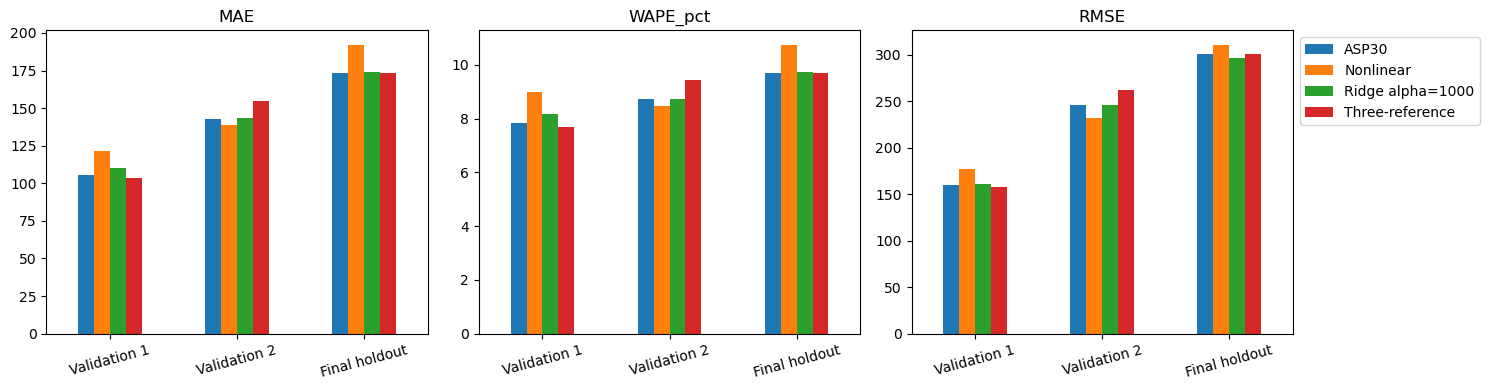

Chosen-model holdout MAE improvement over ASP30 (%): 0.0


,product_id,model,n,MAE,WAPE_pct,RMSE
224,98DG935PJZ,ASP30,13,731.275321,14.019036,1083.945204
68,21WO7047EX,ASP30,2,562.021660,22.166938,562.914476
40,10TBMCG2LC,ASP30,11,470.091675,14.673246,602.064836
236,99FL811XLB,ASP30,1,451.392143,17.323410,451.392143
92,36H9DOF8CS,ASP30,11,437.533867,18.850478,560.211569
204,92MD5916XY,ASP30,9,338.480166,15.444516,365.188684
60,16VT6348MT,ASP30,12,330.921199,12.769053,531.963795
164,67DK817PSS,ASP30,6,309.920992,14.648300,394.483338
88,35ZE1222TH,ASP30,9,303.499610,13.689854,506.568240
28,03ZYIDF2MO,ASP30,10,292.674964,8.573157,345.316591


In [21]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
order=['Validation 1','Validation 2','Final holdout']
for ax,metric in zip(axes,['MAE','WAPE_pct','RMSE']):
    scores.pivot(index='stage',columns='model',values=metric).reindex(order).plot.bar(ax=ax,rot=15)
    ax.set_title(metric);ax.set_xlabel('');ax.get_legend().remove()
axes[-1].legend(loc='upper left',bbox_to_anchor=(1,1))
fig.tight_layout();fig.savefig(OUTPUT/'comparison.png',dpi=170,bbox_inches='tight');plt.show()
product_rows=[]
for (pid,model),g in holdout_predictions.groupby(['product_id','model']):
    product_rows.append(dict(product_id=pid,model=model,**metrics(g.target,g.prediction)))
product_scores=pd.DataFrame(product_rows)
holdout_scores=scores[scores.stage.eq('Final holdout')].set_index('model')
base=holdout_scores.loc['ASP30','MAE']
print('Chosen-model holdout MAE improvement over ASP30 (%):',
      100*(base-holdout_scores.loc[locked_winner,'MAE'])/base if base else np.nan)
display(product_scores[product_scores.model.eq(locked_winner)].sort_values('MAE',ascending=False).head(15))

In [22]:
scores.to_csv(OUTPUT/'model_comparison.csv',index=False)
pooled.to_csv(OUTPUT/'validation_candidates.csv',index=False)
all_predictions.to_csv(OUTPUT/'predictions.csv',index=False)
coverage_table.to_csv(OUTPUT/'coverage.csv',index=False)
weights_table.to_csv(OUTPUT/'blend_weights.csv',index=False)
product_scores.to_csv(OUTPUT/'holdout_product_metrics.csv',index=False)
print('Saved results in:', OUTPUT.resolve())

Saved results in: /Users/shambhavikhanna/Downloads/Capstone/baseline_results
